# MLflow Experiment Tracking: California Housing

Same steps as `train.py` and `predict.py`, with outputs shown inline.

In [1]:
import os
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'

import mlflow
import pandas as pd
from IPython.display import Image, display
from sklearn.datasets import fetch_california_housing

from train import EXPERIMENT_NAME, REGISTERED_MODEL_NAME, TRACKING_URI, run_experiment

mlflow.set_tracking_uri(TRACKING_URI)
print('MLflow', mlflow.__version__, '| tracking URI:', TRACKING_URI)

MLflow 3.17.2 | tracking URI: sqlite:///mlflow.db


## 1. Data

20,640 California districts, 8 features. The target `MedHouseVal` is median house value in $100k.

In [2]:
df = fetch_california_housing(as_frame=True).frame
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
df.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
MedInc,3.87,1.90,0.50,15.00
HouseAge,28.64,12.59,1.00,52.00
AveRooms,5.43,2.47,0.85,141.91
AveBedrms,1.10,0.47,0.33,34.07
Population,1425.48,1132.46,3.00,35682.00
AveOccup,3.07,10.39,0.69,1243.33
Latitude,35.63,2.14,32.54,41.95
Longitude,-119.57,2.00,-124.35,-114.31
MedHouseVal,2.07,1.15,0.15,5.00


## 2. Train and log 12 runs

5 model types with a small hyperparameter sweep. Each config is a nested run under one `model-comparison` parent run. The best run by test RMSE is registered and gets the `champion` alias.

In [4]:
run_experiment(sample_frac=1.0)

2026/11/01 18:53:23 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/01 18:53:23 INFO mlflow.store.db.utils: Updating database tables


2026/11/01 18:53:23 INFO mlflow.tracking.fluent: Experiment with name 'california-housing-regression' does not exist. Creating a new experiment.


ridge-alpha0.1                                RMSE=0.7456  MAE=0.5332  R2=0.5758  CV_RMSE=0.7205


ridge-alpha1.0                                RMSE=0.7456  MAE=0.5332  R2=0.5758  CV_RMSE=0.7205


ridge-alpha10.0                               RMSE=0.7453  MAE=0.5331  R2=0.5761  CV_RMSE=0.7205


... (7 outputs left out)

hist_gradient_boosting-max_iter300-learning_rate0.05 RMSE=0.4531  MAE=0.3010  R2=0.8433  CV_RMSE=0.4657


Successfully registered model 'CaliforniaHousingRegressor'.
2026/11/01 18:54:14 WARNING mlflow.tracking._model_registry.fluent: Run with id ca446a016b7e4fc1bdac670733c4bc49 has no artifacts at artifact path 'model', registering model based on models:/m-37d1e837af5e49cc859f2133a055e778 instead


hist_gradient_boosting-max_iter300-learning_rate0.1 RMSE=0.4541  MAE=0.3015  R2=0.8427  CV_RMSE=0.4658

Leaderboard (sorted by test RMSE):
                                                      run_name     rmse      mae       r2  cv_rmse
          hist_gradient_boosting-max_iter300-learning_rate0.05 0.453097 0.301023 0.843334 0.465686
           hist_gradient_boosting-max_iter300-learning_rate0.1 0.454068 0.301540 0.842661 0.465788
                     random_forest-n_estimators100-max_depth16 0.509205 0.330741 0.802131 0.512760
 gradient_boosting-n_estimators200-learning_rate0.1-max_depth3 0.511381 0.348358 0.800436 0.507337
gradient_boosting-n_estimators200-learning_rate0.05-max_depth3 0.539734 0.369112 0.777694 0.535601
                      random_forest-n_estimators100-max_depth8 0.585525 0.402595 0.738372 0.572928
                                               lasso-alpha0.01 0.740442 0.535326 0.581615 0.724029
                                              lasso-alpha0.001 0.7446

Created version '1' of model 'CaliforniaHousingRegressor'.


## 3. Compare runs from the tracking server

In [5]:
exp = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
parent = mlflow.search_runs([exp.experiment_id], filter_string="tags.mlflow.runName = 'model-comparison'",
                            order_by=['start_time DESC'], max_results=1).iloc[0]
runs = mlflow.search_runs([exp.experiment_id],
                          filter_string=f"tags.mlflow.parentRunId = '{parent.run_id}'",
                          order_by=['metrics.rmse ASC'])
cols = ['tags.mlflow.runName', 'metrics.rmse', 'metrics.mae', 'metrics.r2', 'metrics.cv_rmse', 'metrics.train_time_sec']
table = runs[cols].rename(columns=lambda c: c.split('.')[-1]).round(4)
table

,runName,rmse,mae,r2,cv_rmse,train_time_sec
0,hist_gradient_boosting-max_iter300-learning_ra...,0.4531,0.3010,0.8433,0.4657,2.8399
1,hist_gradient_boosting-max_iter300-learning_ra...,0.4541,0.3015,0.8427,0.4658,0.8798
2,random_forest-n_estimators100-max_depth16,0.5092,0.3307,0.8021,0.5128,0.6077
3,gradient_boosting-n_estimators200-learning_rat...,0.5114,0.3484,0.8004,0.5073,3.4758
4,gradient_boosting-n_estimators200-learning_rat...,0.5397,0.3691,0.7777,0.5356,3.5380
5,random_forest-n_estimators100-max_depth8,0.5855,0.4026,0.7384,0.5729,0.3866
6,lasso-alpha0.01,0.7404,0.5353,0.5816,0.7240,0.0030
7,lasso-alpha0.001,0.7446,0.5331,0.5769,0.7205,0.0044
8,ridge-alpha10.0,0.7453,0.5331,0.5761,0.7205,0.0017
9,ridge-alpha1.0,0.7456,0.5332,0.5758,0.7205,0.0021


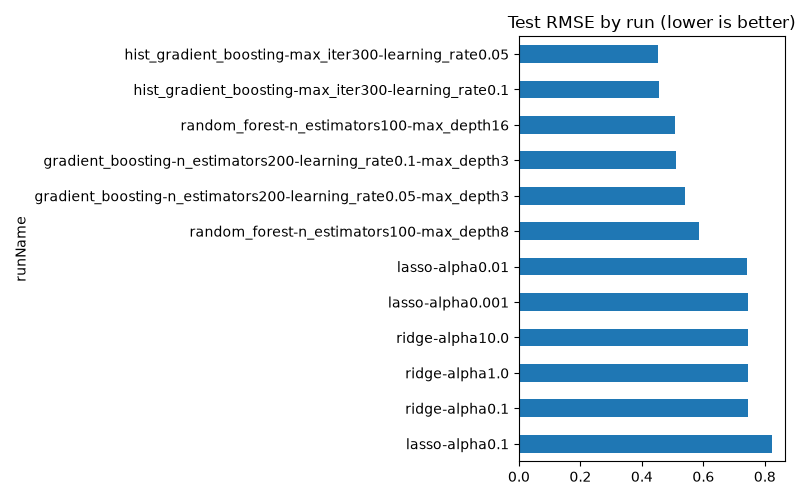

In [6]:
import io
ax = table.set_index('runName')['rmse'].sort_values().plot.barh(figsize=(8, 5), title='Test RMSE by run (lower is better)')
ax.invert_yaxis()
ax.figure.tight_layout()
buf = io.BytesIO()
ax.figure.savefig(buf, format='png', dpi=100)
display(Image(buf.getvalue()))

## 4. Artifacts from the best run

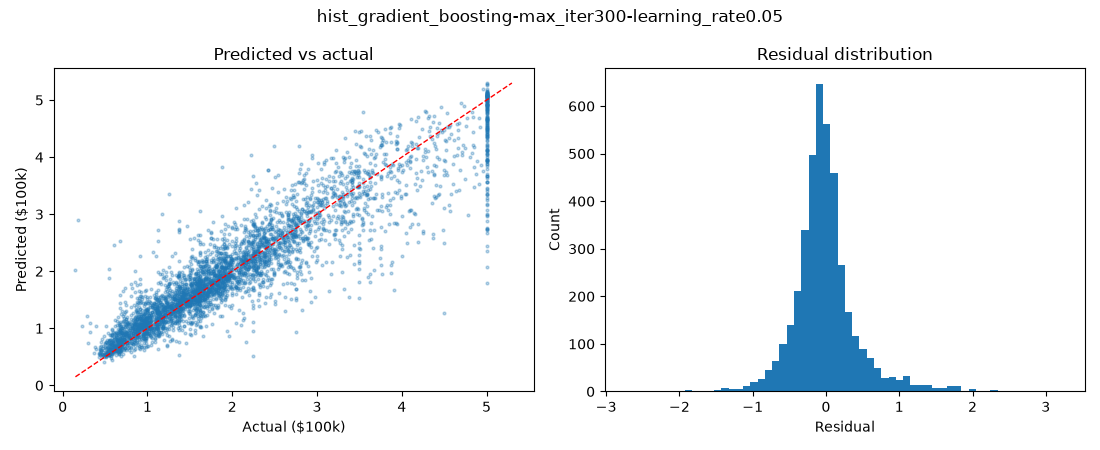

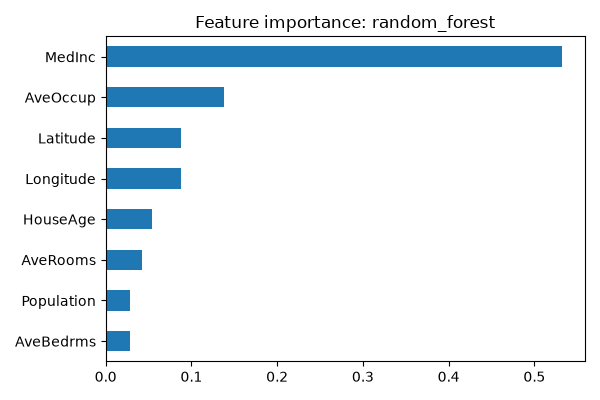

In [7]:
best_run_id = runs.iloc[0].run_id
for art in mlflow.artifacts.list_artifacts(run_id=best_run_id, artifact_path='plots'):
    display(Image(mlflow.artifacts.download_artifacts(run_id=best_run_id, artifact_path=art.path)))

# HistGradientBoosting has no feature_importances_, so show the random forest's instead
rf_id = runs[runs['tags.mlflow.runName'].str.startswith('random_forest')].iloc[0].run_id
display(Image(mlflow.artifacts.download_artifacts(run_id=rf_id, artifact_path='plots/feature_importance.png')))

## 5. Load the champion model from the registry

In [8]:
model = mlflow.pyfunc.load_model(f'models:/{REGISTERED_MODEL_NAME}@champion')
sample = df.drop(columns='MedHouseVal').sample(5, random_state=0)
out = sample[['MedInc', 'HouseAge', 'Latitude', 'Longitude']].copy()
out['actual_$'] = (df.loc[sample.index, 'MedHouseVal'] * 100_000).round()
out['predicted_$'] = (model.predict(sample) * 100_000).round()
out

,MedInc,HouseAge,Latitude,Longitude,actual_$,predicted_$
14740,4.1518,22.0,32.58,-117.05,136900.0,148989.0
10101,5.7796,32.0,33.92,-117.97,241300.0,249789.0
20566,4.3487,29.0,38.65,-121.84,200700.0,151854.0
2670,2.4511,37.0,33.20,-115.60,72500.0,76066.0
15709,5.0049,25.0,37.79,-122.43,460000.0,468769.0


## 6. Serve it as a REST API

```bash
mlflow models serve -m "models:/CaliforniaHousingRegressor@champion" -p 5001 --env-manager local
```

Then send a request (see the README for the `curl` example).